<a href="https://colab.research.google.com/github/oninonins/Machine-learning-/blob/main/JS06%20-%20ANN/Praktikum_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum 3 — Pengaruh Metrik Distance, Jumlah Data, dan Dimensi

Percobaan pada **metrik distance yang berbeda** (**Euclidean L2** vs **Angular/cosine**), **jumlah data** (**1.000** vs **1.000.000**), dan **dimensi data** (**2D** vs **5D**).Total **8 kombinasi**.

- **ENN (exact)** = `IndexFlatL2` / `IndexFlatIP`, brute force tanpa aproksimasi.
- **ANN** = `IndexIVFPQ` (inverted file + product quantization), `nprobe` disetel eksplisit supaya query tidak diam-diam jadi exact.
- **Angular** di FAISS memakai `METRIC_INNER_PRODUCT` dengan vektor dinormalisasi L2 (setara cosine).

Catatan setup supaya perbandingan adil: `m` (jumlah subvektor PQ) disetel `m = d` karena `m` harus membagi `d`; `nbits` menyesuaikan ukuran data (PQ 8-bit butuh >= 9.984 sampel training, jadi N=1.000 memakai 4 bit); `nlist` mengikuti aturan ~ `4*sqrt(N)`. Semua waktu **build index** (`train`, `add`) ikut diukur, bukan hanya waktu query.

In [2]:
!pip install faiss-cpu

In [3]:
import numpy as np, faiss, time, gc, itertools, pandas as pd
import matplotlib.pyplot as plt

K        = 5          # jumlah tetangga terdekat
N_QUERY  = 20         # jumlah query untuk rata-rata waktu
N_RUNS   = 3          # pengulangan query
N_PROBE  = 16         # jumlah inverted list yang dicek per query

N_LISTS  = {1_000: 32, 1_000_000: 4_096}          # ~ 4*sqrt(N)
N_BITS   = {1_000: 4, 1_000_000: 8}              # 8 bit butuh >= 9984 sampel training

METRICS = {
    "Euclidean (L2)":                  faiss.METRIC_L2,
    "Angular (cosine, Inner Product)": faiss.METRIC_INNER_PRODUCT,
}
SIZES = [1_000, 1_000_000]
DIMS  = [2, 5]
SEED  = 42

In [4]:
def make_data(n, d, seed=SEED):
    rng = np.random.default_rng(seed)
    X = rng.random((n, d), dtype=np.float32)
    Q = rng.random((N_QUERY, d), dtype=np.float32)
    return X, Q

def l2_normalize(X):
    return (X / np.maximum(np.linalg.norm(X, axis=1, keepdims=True), 1e-12)).astype('float32')

def build_flat(X, metric):
    index = faiss.IndexFlatL2(X.shape[1]) if metric == faiss.METRIC_L2 else faiss.IndexFlatIP(X.shape[1])
    index.add(X)                      # ENN = brute force, tanpa aproksimasi
    return index

def build_ivfpq(X, nlist, nbits, metric):
    d = X.shape[1]
    m = d                             # jumlah subvektor = dimensi (d harus habis dibagi m)
    quantizer = faiss.IndexFlatL2(d) if metric == faiss.METRIC_L2 else faiss.IndexFlatIP(d)
    index = faiss.IndexIVFPQ(quantizer, d, nlist, m, nbits, metric)
    t0 = time.perf_counter(); index.train(X); t_train = time.perf_counter() - t0
    t0 = time.perf_counter(); index.add(X);    t_add   = time.perf_counter() - t0
    index.nprobe = N_PROBE            # tanpa ini, query bisa diam-diam jadi exact
    return index, t_train, t_add

def time_search(index, Q, n_runs=N_RUNS):
    index.search(Q[:1], K)                        # warm-up
    timings = []
    for _ in range(n_runs):
        t0 = time.perf_counter()
        D, I = index.search(Q, K)
        timings.append((time.perf_counter() - t0) / len(Q) * 1000)   # ms per query
    return float(np.mean(timings)), D, I

def overlap(enn_idx, ann_idx, k=K):
    return float(np.mean([len(set(a[:k]) & set(b[:k])) / k for a, b in zip(enn_idx, ann_idx)]))

In [5]:
rows = []
for (label, metric), n, d in itertools.product(METRICS.items(), SIZES, DIMS):
    X, Q = make_data(n, d)
    if metric == faiss.METRIC_INNER_PRODUCT:
        X, Q = l2_normalize(X), l2_normalize(Q)   # cosine butuh vektor ternormalisasi

    nlist, nbits = N_LISTS[n], N_BITS[n]

    # --- ENN ---
    t0 = time.perf_counter(); flat = build_flat(X, metric); t_enn_build = time.perf_counter() - t0
    w_enn, _, I_enn = time_search(flat, Q)

    # --- ANN ---
    ann, t_train, t_add = build_ivfpq(X, nlist, nbits, metric)
    w_ann, _, I_ann = time_search(ann, Q)

    rows.append({
        "Distance Metrics": label,
        "D (dimensi)": d,
        "Jumlah data": n,
        "nlist": nlist,
        "m / nbits": f"{d} / {nbits}",
        "ENN top-5": list(I_enn[0]),
        "ANN top-5": list(I_ann[0]),
        "Recall@5 (rata-rata)": round(overlap(I_enn, I_ann), 3),
        "Waktu build ANN (s)": round(t_train + t_add, 3),
        "  train (s)": round(t_train, 3),
        "  add (s)": round(t_add, 3),
        "Waktu query ENN (ms)": round(w_enn, 3),
        "Waktu query ANN (ms)": round(w_ann, 3),
    })
    print(f"{label} | d={d} | N={n:,} | recall@5={rows[-1]['Recall@5 (rata-rata)']}")

    del flat, ann, X, Q
    gc.collect()

hasil = pd.DataFrame(rows)
display(hasil)

Euclidean (L2) | d=2 | N=1,000 | recall@5=0.95
Euclidean (L2) | d=5 | N=1,000 | recall@5=0.92
Euclidean (L2) | d=2 | N=1,000,000 | recall@5=0.98
Euclidean (L2) | d=5 | N=1,000,000 | recall@5=0.97
Angular (cosine, Inner Product) | d=2 | N=1,000 | recall@5=0.15
Angular (cosine, Inner Product) | d=5 | N=1,000 | recall@5=0.58
Angular (cosine, Inner Product) | d=2 | N=1,000,000 | recall@5=0.0
Angular (cosine, Inner Product) | d=5 | N=1,000,000 | recall@5=0.62


,Distance Metrics,D (dimensi),Jumlah data,nlist,m / nbits,ENN top-5,ANN top-5,Recall@5 (rata-rata),Waktu build ANN (s),train (s),add (s),Waktu query ENN (ms),Waktu query ANN (ms)
0,Euclidean (L2),2,1000,32,2 / 4,"[258, 17, 971, 187, 794]","[17, 258, 971, 414, 794]",0.95,0.008,0.007,0.001,0.098,0.017
1,Euclidean (L2),5,1000,32,5 / 4,"[812, 34, 550, 962, 251]","[812, 34, 550, 962, 460]",0.92,0.016,0.014,0.002,0.007,0.017
2,Euclidean (L2),2,1000000,4096,2 / 8,"[600900, 695075, 587490, 751043, 109689]","[600900, 695075, 587490, 751043, 109689]",0.98,16.943,11.742,5.201,4.619,0.057
3,Euclidean (L2),5,1000000,4096,5 / 8,"[85158, 586716, 687018, 8630, 91763]","[85158, 586716, 687018, 8630, 91763]",0.97,37.016,23.542,13.474,4.968,0.069
4,"Angular (cosine, Inner Product)",2,1000,32,2 / 4,"[74, 820, 17, 84, 512]","[762, 734, 270, 634, 68]",0.15,0.009,0.008,0.001,0.007,0.012
5,"Angular (cosine, Inner Product)",5,1000,32,5 / 4,"[812, 730, 64, 460, 34]","[812, 866, 204, 460, 34]",0.58,0.017,0.015,0.001,0.009,0.017
6,"Angular (cosine, Inner Product)",2,1000000,4096,2 / 8,"[341136, 309931, 219318, 145656, 125755]","[798513, 683700, 33133, 172611, 78767]",0.00,30.892,19.632,11.261,5.913,0.092
7,"Angular (cosine, Inner Product)",5,1000000,4096,5 / 8,"[233781, 94411, 687018, 914994, 906067]","[233781, 906067, 914994, 94411, 939641]",0.62,98.377,78.535,19.842,11.574,0.067


In [6]:
# Tabel laporan: 5 kolom sesuai template
tabel = pd.DataFrame({
    "Distance Metrics": hasil["Distance Metrics"],
    "Tree": ["nlist=" + str(nl) + ", m/nbits=" + mb for nl, mb in zip(hasil["nlist"], hasil["m / nbits"])],
    "Jumlah data": hasil["Jumlah data"],
    "Hasil Index terdekat ENN vs ANN": [
        f"ENN: {e} vs ANN: {a} (recall@5={r})"
        for e, a, r in zip(hasil["ENN top-5"], hasil["ANN top-5"], hasil["Recall@5 (rata-rata)"])],
    "Waktu komputasi": [
        f"build ANN {b} s; query ENN {e} ms vs ANN {a} ms"
        for b, e, a in zip(hasil["Waktu build ANN (s)"], hasil["Waktu query ENN (ms)"], hasil["Waktu query ANN (ms)"])],
})

display(hasil)                       # detail semua kolom
display(tabel.style.hide(axis='index'))
try:
    print(tabel.to_markdown(index=False))     # butuh paket tabulate
except ImportError:
    print(tabel.to_string(index=False))       # fallback kalau tabulate belum ada

,Distance Metrics,D (dimensi),Jumlah data,nlist,m / nbits,ENN top-5,ANN top-5,Recall@5 (rata-rata),Waktu build ANN (s),train (s),add (s),Waktu query ENN (ms),Waktu query ANN (ms)
0,Euclidean (L2),2,1000,32,2 / 4,"[258, 17, 971, 187, 794]","[17, 258, 971, 414, 794]",0.95,0.008,0.007,0.001,0.098,0.017
1,Euclidean (L2),5,1000,32,5 / 4,"[812, 34, 550, 962, 251]","[812, 34, 550, 962, 460]",0.92,0.016,0.014,0.002,0.007,0.017
2,Euclidean (L2),2,1000000,4096,2 / 8,"[600900, 695075, 587490, 751043, 109689]","[600900, 695075, 587490, 751043, 109689]",0.98,16.943,11.742,5.201,4.619,0.057
3,Euclidean (L2),5,1000000,4096,5 / 8,"[85158, 586716, 687018, 8630, 91763]","[85158, 586716, 687018, 8630, 91763]",0.97,37.016,23.542,13.474,4.968,0.069
4,"Angular (cosine, Inner Product)",2,1000,32,2 / 4,"[74, 820, 17, 84, 512]","[762, 734, 270, 634, 68]",0.15,0.009,0.008,0.001,0.007,0.012
5,"Angular (cosine, Inner Product)",5,1000,32,5 / 4,"[812, 730, 64, 460, 34]","[812, 866, 204, 460, 34]",0.58,0.017,0.015,0.001,0.009,0.017
6,"Angular (cosine, Inner Product)",2,1000000,4096,2 / 8,"[341136, 309931, 219318, 145656, 125755]","[798513, 683700, 33133, 172611, 78767]",0.00,30.892,19.632,11.261,5.913,0.092
7,"Angular (cosine, Inner Product)",5,1000000,4096,5 / 8,"[233781, 94411, 687018, 914994, 906067]","[233781, 906067, 914994, 94411, 939641]",0.62,98.377,78.535,19.842,11.574,0.067


Distance Metrics,Tree,Jumlah data,Hasil Index terdekat ENN vs ANN,Waktu komputasi
Euclidean (L2),"nlist=32, m/nbits=2 / 4",1000,"ENN: [np.int64(258), np.int64(17), np.int64(971), np.int64(187), np.int64(794)] vs ANN: [np.int64(17), np.int64(258), np.int64(971), np.int64(414), np.int64(794)] (recall@5=0.95)",build ANN 0.008 s; query ENN 0.098 ms vs ANN 0.017 ms
Euclidean (L2),"nlist=32, m/nbits=5 / 4",1000,"ENN: [np.int64(812), np.int64(34), np.int64(550), np.int64(962), np.int64(251)] vs ANN: [np.int64(812), np.int64(34), np.int64(550), np.int64(962), np.int64(460)] (recall@5=0.92)",build ANN 0.016 s; query ENN 0.007 ms vs ANN 0.017 ms
Euclidean (L2),"nlist=4096, m/nbits=2 / 8",1000000,"ENN: [np.int64(600900), np.int64(695075), np.int64(587490), np.int64(751043), np.int64(109689)] vs ANN: [np.int64(600900), np.int64(695075), np.int64(587490), np.int64(751043), np.int64(109689)] (recall@5=0.98)",build ANN 16.943 s; query ENN 4.619 ms vs ANN 0.057 ms
Euclidean (L2),"nlist=4096, m/nbits=5 / 8",1000000,"ENN: [np.int64(85158), np.int64(586716), np.int64(687018), np.int64(8630), np.int64(91763)] vs ANN: [np.int64(85158), np.int64(586716), np.int64(687018), np.int64(8630), np.int64(91763)] (recall@5=0.97)",build ANN 37.016 s; query ENN 4.968 ms vs ANN 0.069 ms
"Angular (cosine, Inner Product)","nlist=32, m/nbits=2 / 4",1000,"ENN: [np.int64(74), np.int64(820), np.int64(17), np.int64(84), np.int64(512)] vs ANN: [np.int64(762), np.int64(734), np.int64(270), np.int64(634), np.int64(68)] (recall@5=0.15)",build ANN 0.009 s; query ENN 0.007 ms vs ANN 0.012 ms
"Angular (cosine, Inner Product)","nlist=32, m/nbits=5 / 4",1000,"ENN: [np.int64(812), np.int64(730), np.int64(64), np.int64(460), np.int64(34)] vs ANN: [np.int64(812), np.int64(866), np.int64(204), np.int64(460), np.int64(34)] (recall@5=0.58)",build ANN 0.017 s; query ENN 0.009 ms vs ANN 0.017 ms
"Angular (cosine, Inner Product)","nlist=4096, m/nbits=2 / 8",1000000,"ENN: [np.int64(341136), np.int64(309931), np.int64(219318), np.int64(145656), np.int64(125755)] vs ANN: [np.int64(798513), np.int64(683700), np.int64(33133), np.int64(172611), np.int64(78767)] (recall@5=0.0)",build ANN 30.892 s; query ENN 5.913 ms vs ANN 0.092 ms
"Angular (cosine, Inner Product)","nlist=4096, m/nbits=5 / 8",1000000,"ENN: [np.int64(233781), np.int64(94411), np.int64(687018), np.int64(914994), np.int64(906067)] vs ANN: [np.int64(233781), np.int64(906067), np.int64(914994), np.int64(94411), np.int64(939641)] (recall@5=0.62)",build ANN 98.377 s; query ENN 11.574 ms vs ANN 0.067 ms


| Distance Metrics                | Tree                      |   Jumlah data | Hasil Index terdekat ENN vs ANN                                                                                                                                                                                    | Waktu komputasi                                         |
|:--------------------------------|:--------------------------|--------------:|:-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|:--------------------------------------------------------|
| Euclidean (L2)                  | nlist=32, m/nbits=2 / 4   |          1000 | ENN: [np.int64(258), np.int64(17), np.int64(971), np.int64(187), np.int64(794)] vs ANN: [np.int64(17), np.int64(258), np.int64(971), np.int64(414), np.int64(794)] (recall@5=0.95)                                 | build

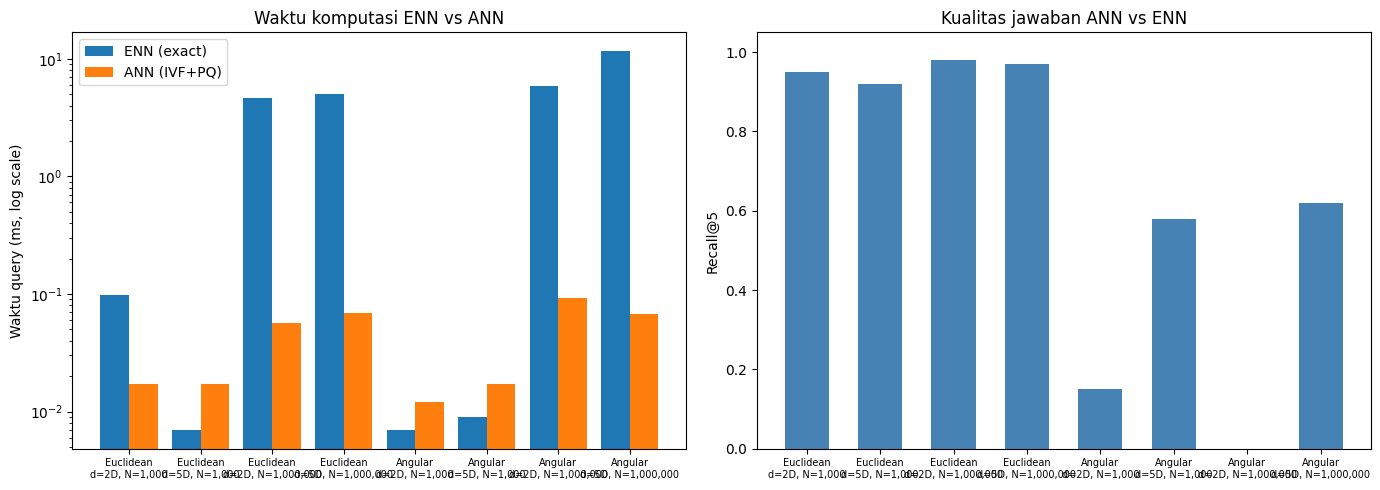

In [7]:
labels = [f"{r['Distance Metrics'].split()[0]}\nd={r['D (dimensi)']}D, N={r['Jumlah data']:,}" for _, r in hasil.iterrows()]
x = np.arange(len(hasil))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].bar(x - 0.2, hasil["Waktu query ENN (ms)"], 0.4, label="ENN (exact)")
ax[0].bar(x + 0.2, hasil["Waktu query ANN (ms)"], 0.4, label="ANN (IVF+PQ)")
ax[0].set_yscale("log")
ax[0].set_xticks(x); ax[0].set_xticklabels(labels, fontsize=7)
ax[0].set_ylabel("Waktu query (ms, log scale)")
ax[0].set_title("Waktu komputasi ENN vs ANN")
ax[0].legend()

ax[1].bar(x, hasil["Recall@5 (rata-rata)"], 0.6, color="steelblue")
ax[1].set_ylim(0, 1.05)
ax[1].set_xticks(x); ax[1].set_xticklabels(labels, fontsize=7)
ax[1].set_ylabel("Recall@5")
ax[1].set_title("Kualitas jawaban ANN vs ENN")

plt.tight_layout(); plt.show()